# Лабораторная работа № 1. Задание 2
## Двумерная задача N тел

### Алгоритм и реализация

Программа nbody.c рассчитывает взаимное
гравитационное движение материальных точек. Вход: число тел N и строки
`m x y vx vy` в СИ (кг, м, с). Выход: CSV `t,x1,y1,...,xN,yN`.
Используется 2D-постановка задачи.

Для каждой пары тел $i<j$ один раз вычисляется
$$\mathbf F_{ij}=Gm_im_j\frac{\mathbf r_j-\mathbf r_i}{|\mathbf r_j-\mathbf r_i|^3},
\qquad G=6.67430\cdot10^{-11}.$$
К суммарной силе, действующей на тело i(j) прибавляется сила $+\mathbf F_{ij}$ ($-\mathbf F_{ij}$). Прибавляя к сумме тел j $-\mathbf F_{ij}$, мы используем третий закон Ньютона. За счёт этого общее число операций сокращается с $N^2$ до $N(N-1)/2$.  

Для расчёта новых координат и скорости тела i мы применяем **метод Эйлера (из методички)**:
$$\mathbf r_i^{k+1}=\mathbf r_i^k+h\mathbf v_i^k,\qquad
\mathbf v_i^{k+1}=\mathbf v_i^k+h\mathbf F_i^k/m_i.$$
Последний шаг укорачивается таким образом, чтобы сумма всех шагов была равна `tend`.

**Основные части кода:**

- `main()` читает вход, создаёт массивы тел и сил, потоки и барьер.
- `worker()` получает диапазон строк `i`, перебирает пары `i < j`, складывает силы
  в свой массив, затем обновляет свои тела и ждёт остальные потоки на барьере.
  Поток 0 записывает CSV. Мьютексы в парном цикле не нужны.
- `write_state()` записывает время и координаты в CSV, а `seconds()` замеряет расчёт.

Расчёт сил требует $O(N^2)$ работы на шаг, локальные массивы — $O(PN)$ памяти.

### Платформа и методика измерений

**CPU:** Intel(R) Core(TM) i3-3240 CPU @ 3.40GHz, 2 физических ядер / 4 логических CPU, x86_64, Linux.
**Компилятор:** GCC; использовались флаги компиляции `-O3 -std=c11 -Wall -Wextra -Wpedantic -pthread` и библиотека `-lm`.

Для N=9, 256, 1024 и 2048 сравнивались P=1,2,4. N=9 — Солнечная система,
остальные наборы — синтетические. Число шагов: 300, 120, 60 и 30 соответственно.
Внутри каждого набора объём работы одинаков для всех P.
`CLOCK_MONOTONIC` измеряет создание потоков, интегрирование и `pthread_join`;
чтение входа и выделение памяти исключены. Для этих замеров запись CSV отключена,
потому что мы хотим сравнить вычисления и синхронизацию, а не скорость диска.
Для каждой конфигурации выполнялись **5 измерений**;
используется **среднее**, ускорение $S_P=\bar T_1/\bar T_P$.

### Результаты для N=2048, 30 шагов

| Потоков | Среднее, с | Минимум, с | Ускорение |
|---:|---:|---:|---:|
| 1 | 1.3354 | 1.3110 | 1.00× |
| 2 | 1.1354 | 1.0146 | 1.18× |
| 4 | 0.7810 | 0.7311 | 1.71× |

Средние времена, минимумы и ускорения сохранены в
`task_2/results/simple_benchmark.csv`. Ниже показаны результаты для всех размеров задачи.


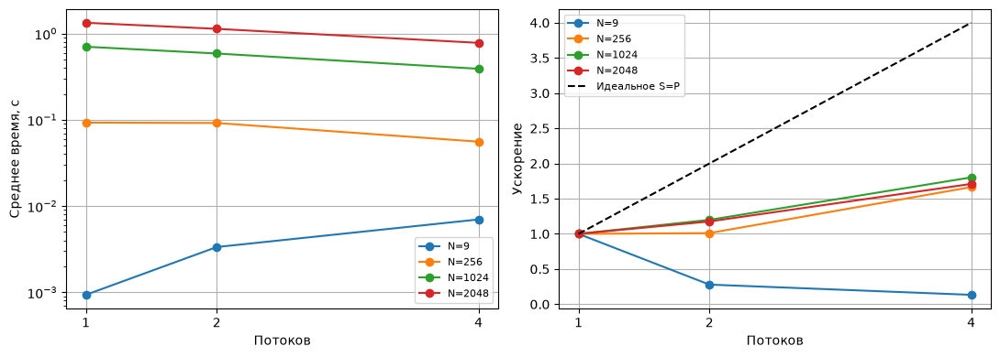

In [9]:
from pathlib import Path
import csv
import matplotlib.pyplot as plt
from IPython.display import display, Image, HTML

ROOT = Path.cwd()
if not (ROOT/'task_2').exists():
    ROOT = ROOT.parent
RESULTS = ROOT/'task_2/results'
with (RESULTS/'simple_benchmark.csv').open() as f:
    measurements = list(csv.DictReader(f))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for n in (9, 256, 1024, 2048):
    rows = [r for r in measurements if int(r['N']) == n]
    p = [int(r['threads']) for r in rows]
    axes[0].plot(p, [float(r['mean_seconds']) for r in rows],
                 marker='o', label=f'N={n}')
    axes[1].plot(p, [float(r['speedup']) for r in rows], 'o-', label=f'N={n}')
axes[0].set(yscale='log', xlabel='Потоков', ylabel='Среднее время, с')
axes[1].plot([1,2,4], [1,2,4], 'k--', label='Идеальное S=P')
axes[1].set(xlabel='Потоков', ylabel='Ускорение')
for ax in axes:
    ax.set_xticks([1,2,4]); ax.grid(True); ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Визуализация
Показаны Солнце и 8 планет за **2 года**, шаг **300 с**, 2 потока, запись раз в сутки.
Массы и расстояния — [NASA](https://nssdc.gsfc.nasa.gov/planetary/factsheet/planet_table_ratio.html)
и [Sun Fact Sheet](https://nssdc.gsfc.nasa.gov/planetary/factsheet/sunfact.html).
Начальные фазы выбраны, скорости приблизительно круговые; все тела движутся в одной
плоскости. На рисунке координаты отсчитываются
от движущегося Солнца; внешние планеты за два года проходят только дуги.
Анимация также доступна в [отдельном HTML](task_2/results/solar_animation.html).

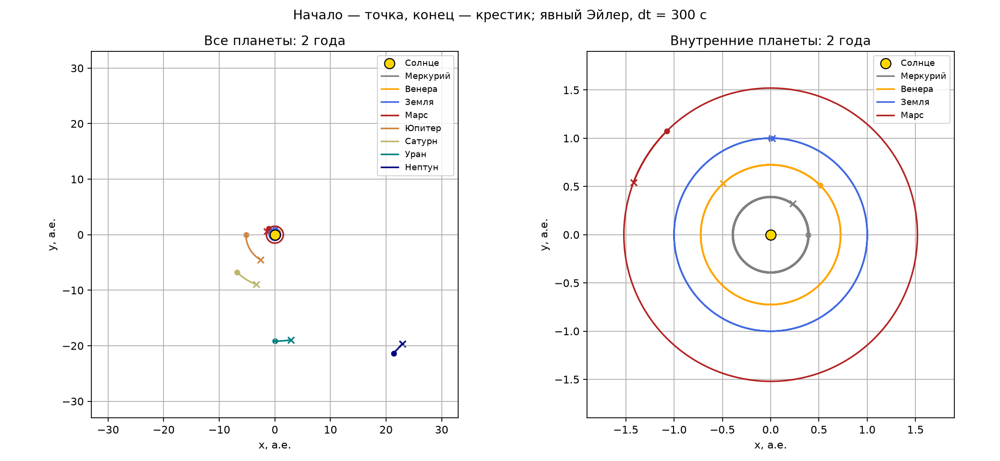

In [8]:
display(Image(filename=str(RESULTS/'solar_orbits.png')))
display(HTML((RESULTS/'solar_animation.html').read_text()))

### Вывод

Реализован параллельный расчёт с однократной обработкой каждой пары.
Для N=2048 четыре потока дали ускорение **1.71×**;
для 9 тел запуск с несколькими потоками оказался медленнее одного, потому что
затраты на создание потоков и синхронизацию больше вычислительной работы.
и постепенно накапливает численную ошибку, поэтому для долгих расчётов
шаг времени нужно выбирать достаточно маленьким.